# Exploring a PNN in Coherent QPSK Transmission

This notebook establishes a physical baseline and compares the effect of a PNN in a coherent QPSK system. BER is the primary figure of merit. It evaluates (1) chromatic dispersion without nonlinearity versus distance and (2) dispersion plus the Kerr effect versus launch power over a 1000 km link. For each analysis and linewidth, a PNN is trained separately and then evaluated with fixed weights.

The model uses an IQ-MZM QPSK transmitter, a seventh-order Gaussian electrical filter, and three equal TX/LO linewidths: 0, 100 kHz, and 1 MHz. TX and LO phases are independent realizations. This baseline has no digital dispersion compensation or phase recovery.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import json

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.dsp.transmitter import (
    ElectricalFilterParams,
    IQMZMParams,
    generate_qpsk_symbols,
    modulate_optical_signal,
)
from src.dsp.fiber import FiberParams, fibra_monomodo
from src.utils.edfa import EDFAIdeal
from src.dsp.noise_models import generate_wiener_phase_noise
from src.dsp.receiver import coherent_detection, cd_compensation, sample_to_symbols, demap_qpsk
from src.utils.metrics import calculate_ber

FIG_DIR = PROJECT_ROOT / 'artifacts' / 'figures' / 'pnn_edfa'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f'Raiz do projeto: {PROJECT_ROOT}')
from src.utils.pnn_model import PhotonicNeuralNetwork
from scripts.optimize_pnn_pso import particle_swarm_optimize


Raiz do projeto: D:\gits\PHOTONICS_2026\Codigos\python\pnn_coerente


## 1. Parameters and Link Configuration

`SPAN_LENGTH_KM` is the fiber-span length used throughout the link. Total distance must be an integer multiple of this value; the notebook stops otherwise to avoid shorter final spans. Change this parameter to compare 50, 100, or 200 km spans.

Inline EDFAs exactly compensate each span's loss. The terminal EDFA has fixed gain, and a variable attenuator adjusts receiver input power to `RX_TARGET_DBM`. EDFAs are ideal at this stage: ASE, noise figure, and saturation are not included.

In [2]:
NUM_SYMBOLS = 2**12
SPS = 8
SYMBOL_RATE = 10e9
WAVELENGTH = 1550e-9

# Span configuration: every span has this exact length.
SPAN_LENGTH_KM = 50.0  # experimente 50.0 ou 200.0 km
DISTANCE_SWEEP_MAX_KM = 1000.0
DISTANCE_NONLINEAR_KM = 1000.0
NUM_STEPS_PER_SPAN = 10

# Inline EDFA compensates alpha_db * SPAN_LENGTH_KM for each span.
# The EDFA and attenuator stage at the receiver input sets this power.
RX_EDFA_GAIN_DB = 20.0
RX_TARGET_DBM = 0.0

TX_POWER_DISPERSION_DBM = 0.0
POWER_SWEEP_DBM = np.arange(-20.0, 20.1, 2.0)
LINEWIDTHS_HZ = np.array([0.0, 100e3, 1e6])

FIBER_PARAMS = FiberParams(
    alpha_db=0.2,
    d_1550=16.0,
    slope_s=0.09,
    n2=3.2e-20,
    a_eff=70e-12,
)
IQ_PARAMS = IQMZMParams(electrical_response=False)
EDFA_MODEL = EDFAIdeal  # replacement point for a future analytical model
FILTER_PARAMS = ElectricalFilterParams(
    tipo='gaussiano',
    largura_banda_hz=2*SYMBOL_RATE,
    ordem=7,
)
MODULATOR = 'iq_mzm'


# PNN: each model is trained for its own scenario and linewidth.
PNN_NUM_CHANNELS = 16
PNN_BASE_DELAY_PS = 25.0
PNN_NORMALIZE_POWER = True
PNN_TRAIN_SYMBOLS = 2**10
PNN_TRAIN_SEED = 20261101
PNN_SWARM_SIZE = 30
PNN_ITERATIONS = 50
PNN_NONLINEAR_TRAIN_POWER_DBM = 0.0
PNN_POWER_SWEEP_SWARM_SIZE = 30
PNN_POWER_SWEEP_ITERATIONS = 50
PNN_DISTANCE_SWEEP_SWARM_SIZE = 30
PNN_DISTANCE_SWEEP_ITERATIONS = 50

if SPAN_LENGTH_KM <= 0:
    raise ValueError('SPAN_LENGTH_KM deve ser positivo.')
if DISTANCE_SWEEP_MAX_KM % SPAN_LENGTH_KM != 0:
    raise ValueError('DISTANCE_SWEEP_MAX_KM must be a multiple of SPAN_LENGTH_KM.')
if DISTANCE_NONLINEAR_KM % SPAN_LENGTH_KM != 0:
    raise ValueError('DISTANCE_NONLINEAR_KM must be a multiple of SPAN_LENGTH_KM.')
if RX_EDFA_GAIN_DB < RX_TARGET_DBM - min(TX_POWER_DISPERSION_DBM, POWER_SWEEP_DBM.min()):
    raise ValueError('The terminal EDFA gain is insufficient to reach the target power.')

DISTANCES_KM = np.arange(
    SPAN_LENGTH_KM, DISTANCE_SWEEP_MAX_KM + SPAN_LENGTH_KM, SPAN_LENGTH_KM
)
print(f'Span: {SPAN_LENGTH_KM:g} km | EDFAs per 1000 km: {DISTANCE_NONLINEAR_KM / SPAN_LENGTH_KM:g}')
print(f'Target receiver power: {RX_TARGET_DBM:.1f} dBm')
print(f'Larguras de linha TX = LO: {LINEWIDTHS_HZ} Hz')


Span: 50 km | EDFAs per 1000 km: 20
Target receiver power: 0.0 dBm
Larguras de linha TX = LO: [      0.  100000. 1000000.] Hz


## 2. Propagation and Power Functions

Each span propagates the field through the fiber and applies an ideal EDFA with gain equal to that span's loss. The terminal stage applies fixed gain and calculates the attenuation needed to reach the target receiver power.

In [3]:
def mean_power_dbm(field):
    """Mean optical envelope power in dBm."""
    power_w = np.mean(np.abs(field) ** 2)
    return 10.0 * np.log10(power_w / 1e-3)


def propagate_spanned_link(
    field, t, total_length_km, include_nonlinearity,
    span_length_km=SPAN_LENGTH_KM, fiber_params=FIBER_PARAMS,
    num_steps_per_span=NUM_STEPS_PER_SPAN,
):
    """Propagate uniform spans, each followed by a gain-compensating EDFA."""
    n_spans_float = total_length_km / span_length_km
    n_spans = int(round(n_spans_float))
    if n_spans <= 0 or not np.isclose(n_spans_float, n_spans, rtol=0.0, atol=1e-9):
        raise ValueError(
            f'{total_length_km:g} km is not an integer multiple of the span length '
            f'{span_length_km:g} km.'
        )

    regime = 1 if include_nonlinearity else 0
    field_out = np.asarray(field, dtype=complex).copy()
    span_loss_db = fiber_params.alpha_db * span_length_km
    inline_edfa = EDFA_MODEL(gain_db=span_loss_db)

    for _ in range(n_spans):
        field_out, _, _ = fibra_monomodo(
            t,
            field_out,
            wavelength=WAVELENGTH,
            t0=1.0 / SYMBOL_RATE,
            length_km=span_length_km,
            regime=regime,
            params=fiber_params,
            num_steps=num_steps_per_span,
        )
        # The ideal EDFA compensates this span's passive loss.
        field_out = inline_edfa.amplify(field_out)

    return field_out


def receiver_edfa_and_attenuator(field, target_dbm=RX_TARGET_DBM, edfa_gain_db=RX_EDFA_GAIN_DB):
    """Apply a fixed-gain terminal EDFA and ideal VOA to set received power."""
    receiver_edfa = EDFA_MODEL(gain_db=edfa_gain_db)
    amplified = receiver_edfa.amplify(field)
    power_after_edfa_dbm = mean_power_dbm(amplified)
    attenuation_db = power_after_edfa_dbm - target_dbm
    if attenuation_db < -1e-9:
        raise ValueError(
            'The terminal EDFA did not raise the signal to the target power; '
            'aumente RX_EDFA_GAIN_DB.'
        )
    attenuation_db = max(0.0, attenuation_db)
    received = amplified * 10.0 ** (-attenuation_db / 20.0)
    return received, attenuation_db, power_after_edfa_dbm


## 3. Reference Signal and Phase Noise

The same QPSK frame is reused in both sweeps. TX and LO phases are independent Wiener processes with the same linewidth in each case. The realizations remain fixed across distances and launch powers to make curve points easier to compare.

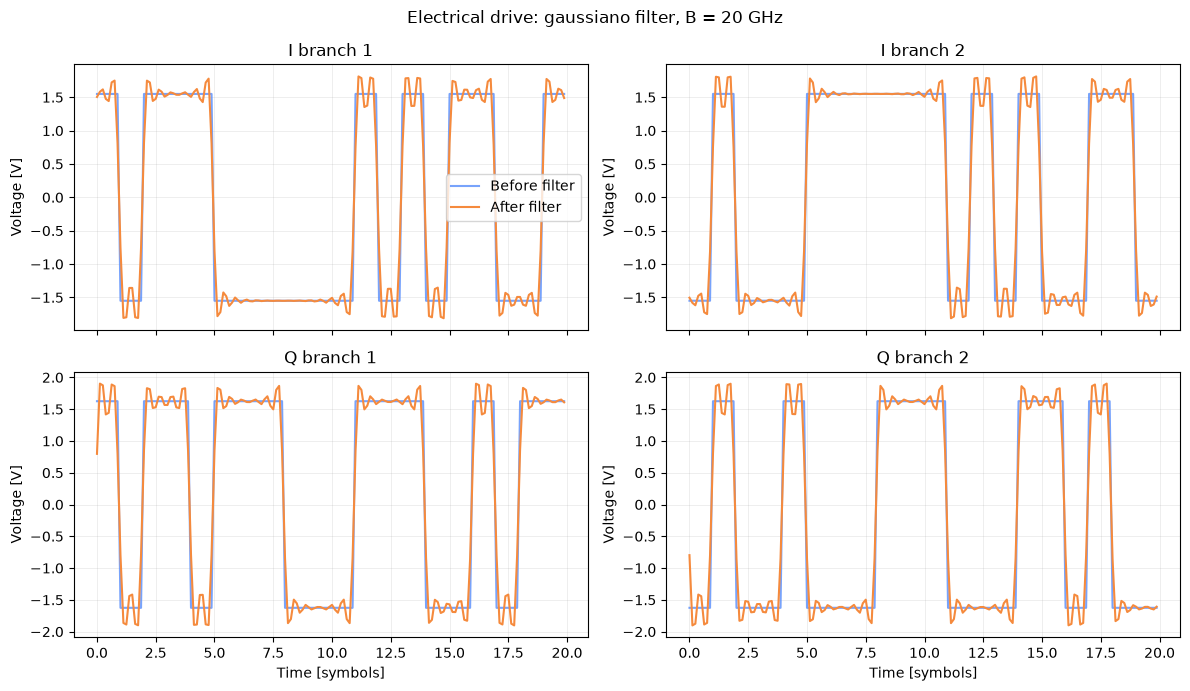

Symbols: 4096 | samples/symbol: 8 | dt: 1.250e-11 s
Reference mean power: 0.00 dBm


In [4]:
symbols, bits = generate_qpsk_symbols(NUM_SYMBOLS, seed=42)

# 0 dBm reference; the power sweep scales the field linearly.
u_tx_0dbm, t, dt = modulate_optical_signal(
    symbols,
    sps=SPS,
    launch_power_dbm=0.0,
    symbol_rate=SYMBOL_RATE,
    modulator=MODULATOR,
    iq_params=IQ_PARAMS,
    filter_params=FILTER_PARAMS,
    plot_filter=True,
    n_plot=20,
)

phase_noise = {}
for idx, linewidth_hz in enumerate(LINEWIDTHS_HZ):
    phase_tx = generate_wiener_phase_noise(
        len(t), dt, float(linewidth_hz), seed=1000 + idx
    )
    phase_lo = generate_wiener_phase_noise(
        len(t), dt, float(linewidth_hz), seed=2000 + idx
    )
    phase_noise[float(linewidth_hz)] = (phase_tx, phase_lo)

print(f'Symbols: {NUM_SYMBOLS} | samples/symbol: {SPS} | dt: {dt:.3e} s')
print(f'Reference mean power: {mean_power_dbm(u_tx_0dbm):.2f} dBm')


## 4. Analysis 1 — BER vs. Distance: Chromatic Dispersion

The fiber retains its physical attenuation and ideal inline EDFAs, but propagation uses the linear regime (`regime=0`) without Kerr. The curves compare reception without CDC and DSP chromatic dispersion compensation applied after coherent detection and before symbol sampling. Linewidth is also varied: 0 Hz isolates dispersion, while 100 kHz and 1 MHz include independent phase noise.

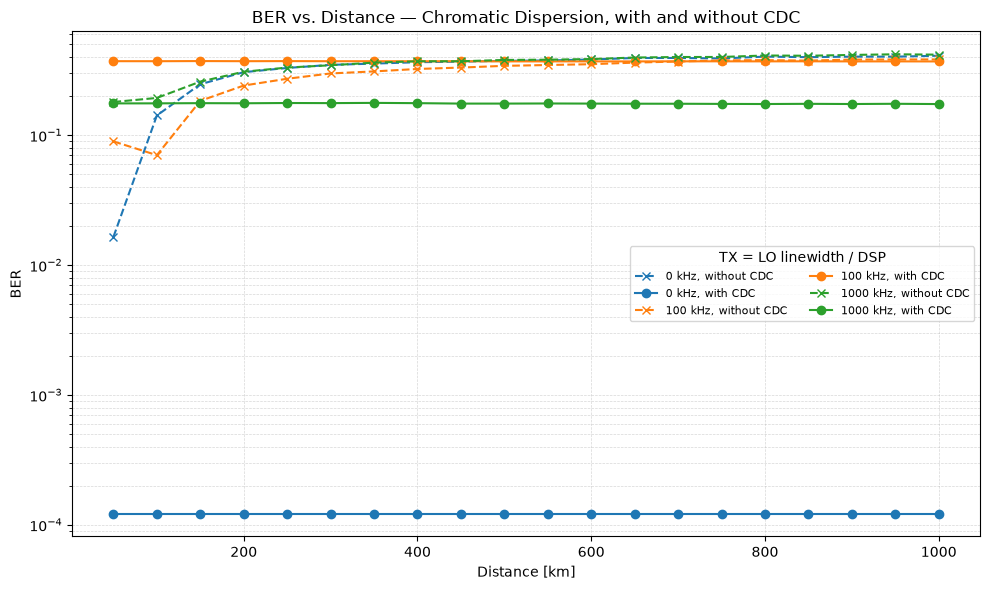

Receiver power (min/max): -0.0000 / 0.0000 dBm
Zero BER values are plotted at the floor 1.22e-04 in the plot.


In [5]:
ber_vs_distance_no_cdc = {float(lw): [] for lw in LINEWIDTHS_HZ}
ber_vs_distance_with_cdc = {float(lw): [] for lw in LINEWIDTHS_HZ}
rx_power_distance = {float(lw): [] for lw in LINEWIDTHS_HZ}

for linewidth_hz in LINEWIDTHS_HZ:
    phase_tx, phase_lo = phase_noise[float(linewidth_hz)]
    for distance_km in DISTANCES_KM:
        field_tx = u_tx_0dbm * np.exp(1j * phase_tx)
        field_link = propagate_spanned_link(
            field_tx, t, distance_km, include_nonlinearity=False
        )
        field_rx, atten_db, _ = receiver_edfa_and_attenuator(field_link)
        rx_power_distance[float(linewidth_hz)].append(mean_power_dbm(field_rx))

        r_bb = coherent_detection(field_rx, phase_lo=phase_lo)
        rx_symbols = sample_to_symbols(r_bb, sps=SPS)
        ber_no_cdc = calculate_ber(bits, demap_qpsk(rx_symbols))
        ber_vs_distance_no_cdc[float(linewidth_hz)].append(ber_no_cdc)

        r_bb_cdc = cd_compensation(
            r_bb,
            dt=dt,
            length_km=distance_km,
            dispersion_d=FIBER_PARAMS.d_1550,
        )
        rx_symbols_cdc = sample_to_symbols(r_bb_cdc, sps=SPS)
        ber_with_cdc = calculate_ber(bits, demap_qpsk(rx_symbols_cdc))
        ber_vs_distance_with_cdc[float(linewidth_hz)].append(ber_with_cdc)

BER_PLOT_FLOOR = 1.0 / (2 * NUM_SYMBOLS)
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['tab:blue', 'tab:orange', 'tab:green']
for linewidth_hz, color in zip(LINEWIDTHS_HZ, colors):
    values_no = np.asarray(ber_vs_distance_no_cdc[float(linewidth_hz)])
    values_cdc = np.asarray(ber_vs_distance_with_cdc[float(linewidth_hz)])
    ax.semilogy(
        DISTANCES_KM,
        np.maximum(values_no, BER_PLOT_FLOOR),
        linestyle='--', marker='x', color=color,
        label=f'{linewidth_hz / 1e3:g} kHz, without CDC',
    )
    ax.semilogy(
        DISTANCES_KM,
        np.maximum(values_cdc, BER_PLOT_FLOOR),
        linestyle='-', marker='o', color=color,
        label=f'{linewidth_hz / 1e3:g} kHz, with CDC',
    )
ax.set_title('BER vs. Distance — Chromatic Dispersion, with and without CDC')
ax.set_xlabel('Distance [km]')
ax.set_ylabel('BER')
ax.grid(True, which='both', linestyle='--', alpha=0.5)
ax.legend(title='TX = LO linewidth / DSP', ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / 'pnn_analise_1_ber_vs_distancia_com_sem_cdc.png', dpi=250)
plt.show()

rx_power_distance_values = [value for curve in rx_power_distance.values() for value in curve]
print(f'Receiver power (min/max): {np.min(rx_power_distance_values):.4f} / {np.max(rx_power_distance_values):.4f} dBm')
print(f'Zero BER values are plotted at the floor {BER_PLOT_FLOOR:.2e} in the plot.')


## 5. Analysis 2 — BER vs. Launch Power: Dispersion and Nonlinearity

The link is 1000 km and uses SSFM (`regime=1`) with dispersion and Kerr. Launch power varies from −20 to +20 dBm. Each span EDFA compensates fiber loss, keeping approximately the same power at the start of each span. After the last span, a fixed-gain terminal EDFA and variable attenuator set the receiver input to 0 dBm. BER is compared with and without CDC, applied after coherent detection and before symbol sampling.

The notebook propagates the signal for each launch-power and linewidth combination. Since TX and LO phase noise are independent and TX phase is applied before the fiber, phase noise can also interact with dispersion and nonlinearity.

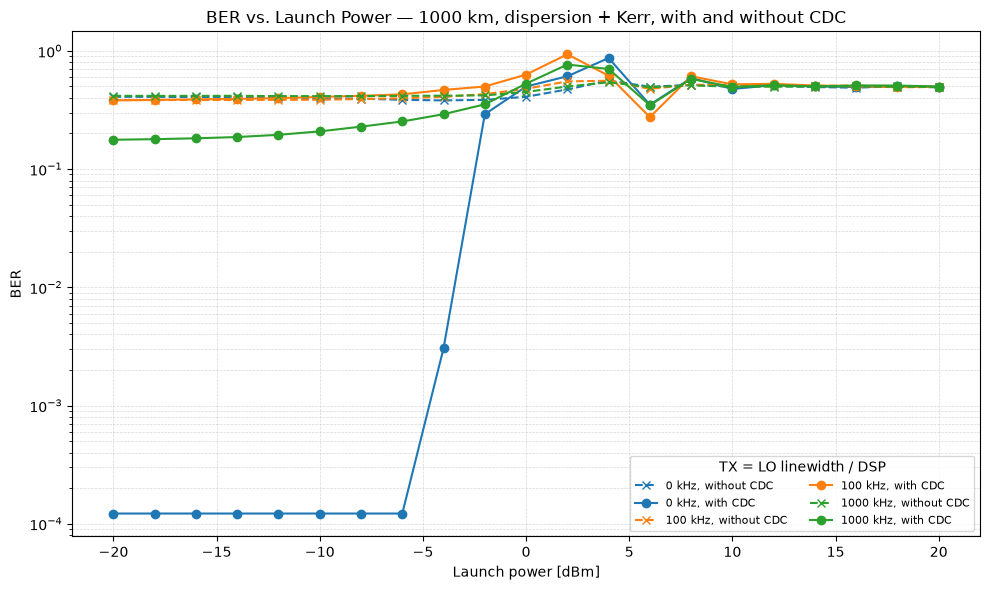

Measured receiver power (min/max): -0.0000 / 0.0000 dBm
Terminal VOA attenuation (min/max): 0.00 / 40.00 dB
EDFA terminal: ganho fixo de 20.0 dB; alvo do receptor: 0.0 dBm.


In [6]:
ber_vs_power_no_cdc = {float(lw): [] for lw in LINEWIDTHS_HZ}
ber_vs_power_with_cdc = {float(lw): [] for lw in LINEWIDTHS_HZ}
rx_power_sweep = []
rx_stage_attenuation = []

for launch_power_dbm in POWER_SWEEP_DBM:
    # Scale the 0 dBm reference field to the desired launch power.
    tx_field = u_tx_0dbm * 10.0 ** (launch_power_dbm / 20.0)

    for linewidth_hz in LINEWIDTHS_HZ:
        phase_tx, phase_lo = phase_noise[float(linewidth_hz)]
        field_tx = tx_field * np.exp(1j * phase_tx)
        field_link = propagate_spanned_link(
            field_tx,
            t,
            DISTANCE_NONLINEAR_KM,
            include_nonlinearity=True,
        )
        field_rx, atten_db, power_after_rx_edfa_dbm = receiver_edfa_and_attenuator(field_link)
        rx_power_sweep.append(mean_power_dbm(field_rx))
        rx_stage_attenuation.append(atten_db)

        r_bb = coherent_detection(field_rx, phase_lo=phase_lo)
        rx_symbols = sample_to_symbols(r_bb, sps=SPS)
        ber_no_cdc = calculate_ber(bits, demap_qpsk(rx_symbols))
        ber_vs_power_no_cdc[float(linewidth_hz)].append(ber_no_cdc)

        r_bb_cdc = cd_compensation(
            r_bb,
            dt=dt,
            length_km=DISTANCE_NONLINEAR_KM,
            dispersion_d=FIBER_PARAMS.d_1550,
        )
        rx_symbols_cdc = sample_to_symbols(r_bb_cdc, sps=SPS)
        ber_with_cdc = calculate_ber(bits, demap_qpsk(rx_symbols_cdc))
        ber_vs_power_with_cdc[float(linewidth_hz)].append(ber_with_cdc)

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['tab:blue', 'tab:orange', 'tab:green']
for linewidth_hz, color in zip(LINEWIDTHS_HZ, colors):
    values_no = np.asarray(ber_vs_power_no_cdc[float(linewidth_hz)])
    values_cdc = np.asarray(ber_vs_power_with_cdc[float(linewidth_hz)])
    ax.semilogy(
        POWER_SWEEP_DBM,
        np.maximum(values_no, BER_PLOT_FLOOR),
        linestyle='--', marker='x', color=color,
        label=f'{linewidth_hz / 1e3:g} kHz, without CDC',
    )
    ax.semilogy(
        POWER_SWEEP_DBM,
        np.maximum(values_cdc, BER_PLOT_FLOOR),
        linestyle='-', marker='o', color=color,
        label=f'{linewidth_hz / 1e3:g} kHz, with CDC',
    )
ax.set_title(f'BER vs. Launch Power — {DISTANCE_NONLINEAR_KM:g} km, dispersion + Kerr, with and without CDC')
ax.set_xlabel('Launch power [dBm]')
ax.set_ylabel('BER')
ax.grid(True, which='both', linestyle='--', alpha=0.5)
ax.legend(title='TX = LO linewidth / DSP', ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / 'pnn_analise_2_ber_vs_potencia_com_sem_cdc.png', dpi=250)
plt.show()

print(f'Measured receiver power (min/max): {np.min(rx_power_sweep):.4f} / {np.max(rx_power_sweep):.4f} dBm')
print(f'Terminal VOA attenuation (min/max): {np.min(rx_stage_attenuation):.2f} / {np.max(rx_stage_attenuation):.2f} dB')
print(f'EDFA terminal: ganho fixo de {RX_EDFA_GAIN_DB:.1f} dB; alvo do receptor: {RX_TARGET_DBM:.1f} dBm.')


## 6. Independent PNN Training for Each Analysis

Six PNNs are trained: one for each of the two analyses and each linewidth. For the distance analysis, training uses the maximum distance and `TX_POWER_DISPERSION_DBM`; for the power analysis, it uses `DISTANCE_NONLINEAR_KM` and a reference launch power of 0 dBm. Each PNN's weights are fixed while its corresponding curve is evaluated.

Training uses a short QPSK sequence and dedicated phase-noise realizations. Evaluation reuses the longer sequence and independent baseline realizations. The objective is BER without CDC, so PSO trains the PNN to compensate for the link; PNN followed by CDC is also measured.

dispersion + CDC, linewidth=0 kHz: training BER=0
dispersion, linewidth=0 kHz: training BER=0.215332, evaluations=1530
dispersion + CDC, linewidth=100 kHz: training BER=0
dispersion, linewidth=100 kHz: training BER=0.217773, evaluations=1530
dispersion + CDC, linewidth=1000 kHz: training BER=0.212891
dispersion, linewidth=1000 kHz: training BER=0.3125, evaluations=1530
nonlinear + CDC, linewidth=0 kHz: training BER=0.0151367
nonlinear, linewidth=0 kHz: training BER=0.23877, evaluations=1530
nonlinear + CDC, linewidth=100 kHz: training BER=0.000488281
nonlinear, linewidth=100 kHz: training BER=0.234863, evaluations=1530
nonlinear + CDC, linewidth=1000 kHz: training BER=0.226562
nonlinear, linewidth=1000 kHz: training BER=0.328125, evaluations=1530
Independent training completed for 50 km.
Independent training completed for 100 km.
Independent training completed for 150 km.
Independent training completed for 200 km.
Independent training completed for 250 km.
Independent training complete

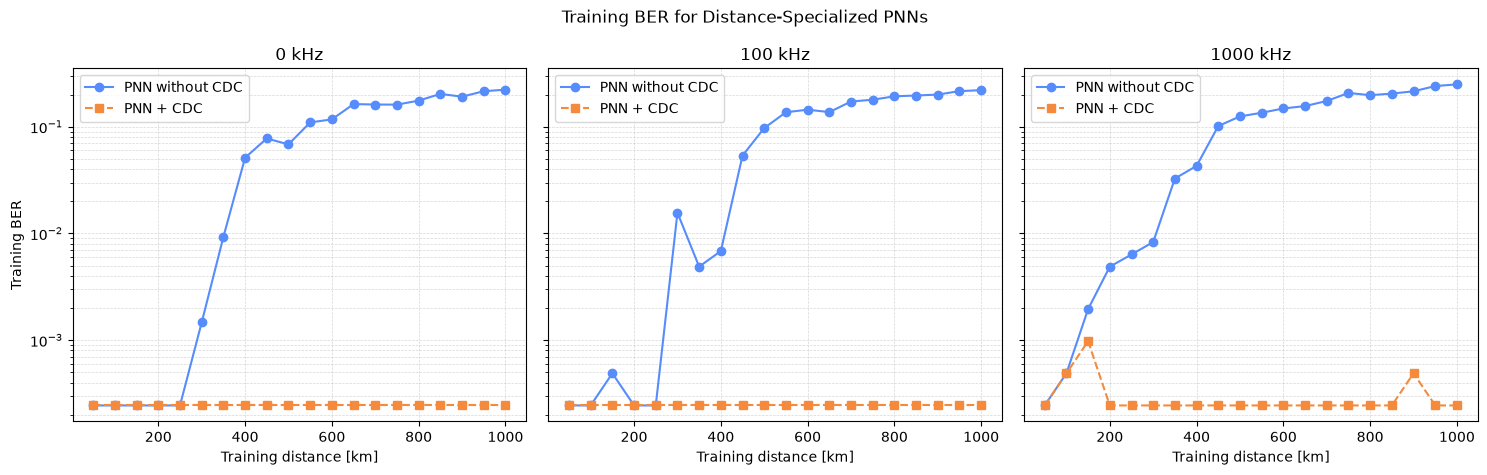

Power-based training: -20 dBm, linewidth=0 kHz, BER=0.217285, avaliacoes=1530
Power-based training: -20 dBm, linewidth=100 kHz, BER=0.230957, avaliacoes=1530
Power-based training: -20 dBm, linewidth=1000 kHz, BER=0.236328, avaliacoes=1530
Power-based training: -18 dBm, linewidth=0 kHz, BER=0.229004, avaliacoes=1530
Power-based training: -18 dBm, linewidth=100 kHz, BER=0.230469, avaliacoes=1530
Power-based training: -18 dBm, linewidth=1000 kHz, BER=0.245117, avaliacoes=1530
Power-based training: -16 dBm, linewidth=0 kHz, BER=0.234863, avaliacoes=1530
Power-based training: -16 dBm, linewidth=100 kHz, BER=0.251465, avaliacoes=1530
Power-based training: -16 dBm, linewidth=1000 kHz, BER=0.228516, avaliacoes=1530
Power-based training: -14 dBm, linewidth=0 kHz, BER=0.234863, avaliacoes=1530
Power-based training: -14 dBm, linewidth=100 kHz, BER=0.23584, avaliacoes=1530
Power-based training: -14 dBm, linewidth=1000 kHz, BER=0.257812, avaliacoes=1530
Power-based training: -12 dBm, linewidth=0 kH

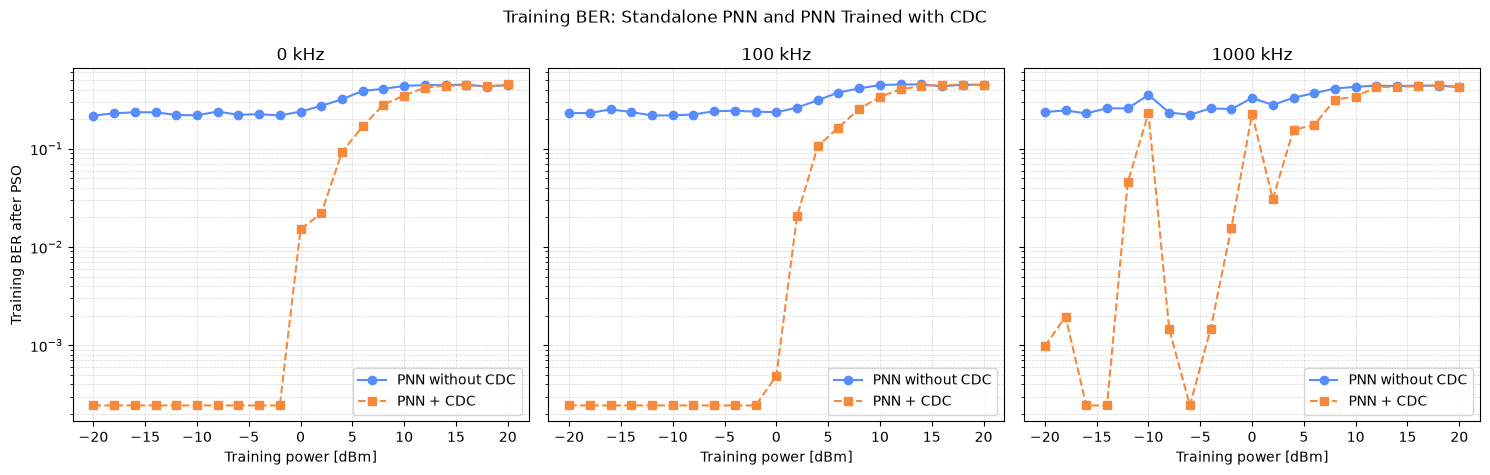

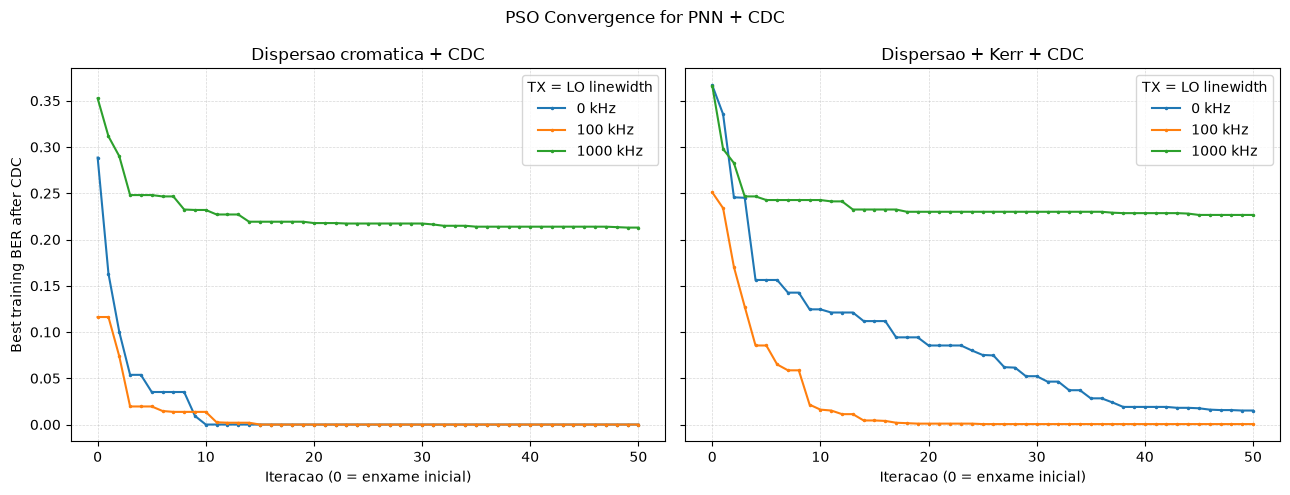

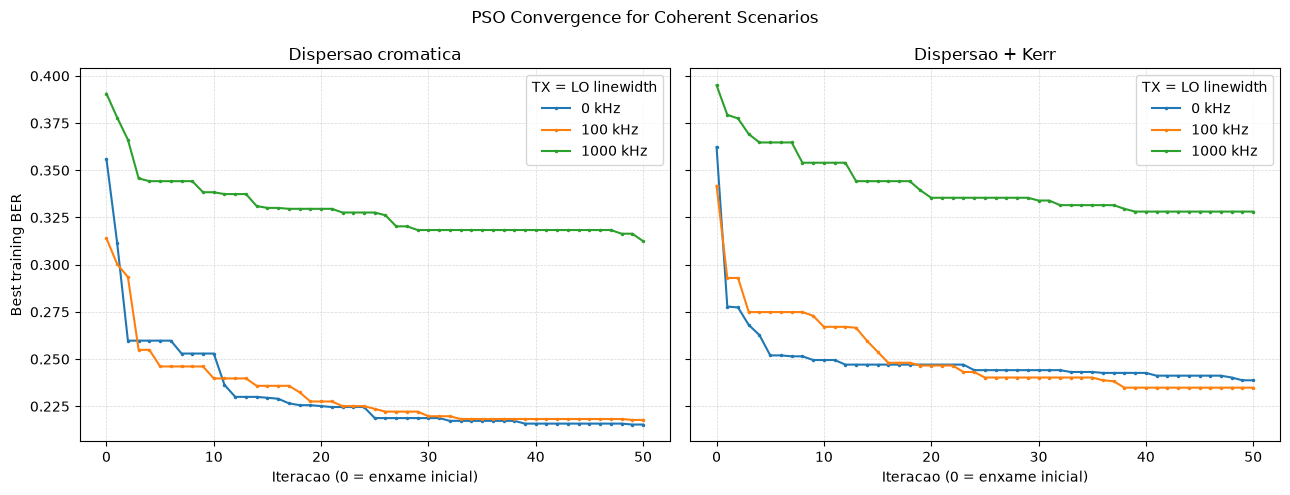

Weights and training histories saved to: D:\gits\PHOTONICS_2026\Codigos\python\pnn_coerente\artifacts\models\pnn_coerente_pso_treinamento.json


In [7]:
# Short training sequence, separate from the evaluation (symbols, bits) sequence.
train_symbols, train_bits = generate_qpsk_symbols(
    PNN_TRAIN_SYMBOLS, seed=PNN_TRAIN_SEED
)
train_tx_0dbm, t_train, dt_train = modulate_optical_signal(
    train_symbols,
    sps=SPS,
    launch_power_dbm=0.0,
    symbol_rate=SYMBOL_RATE,
    modulator=MODULATOR,
    iq_params=IQ_PARAMS,
    filter_params=FILTER_PARAMS,
    plot_filter=False,
    n_plot=0,
)

pnn_model = PhotonicNeuralNetwork(
    num_channels=PNN_NUM_CHANNELS,
    base_delay_ps=PNN_BASE_DELAY_PS,
    normalize_power=PNN_NORMALIZE_POWER,
    responsivity=1.0,
)
pnn_bounds = [(0.0, 1.0)] * PNN_NUM_CHANNELS + [(-np.pi, np.pi)] * PNN_NUM_CHANNELS
pnn_training_results = {}
pnn_joint_cdc_results = {}
joint_training_histories = {'dispersion': {}, 'nonlinear': {}}
training_histories = {'dispersion': {}, 'nonlinear': {}}

for scenario, distance_km, include_nonlinearity, launch_power_dbm in [
    ('dispersion', DISTANCE_SWEEP_MAX_KM, False, TX_POWER_DISPERSION_DBM),
    ('nonlinear', DISTANCE_NONLINEAR_KM, True, PNN_NONLINEAR_TRAIN_POWER_DBM),
]:
    train_field_at_power = train_tx_0dbm * 10.0 ** (launch_power_dbm / 20.0)
    for linewidth_index, linewidth_hz in enumerate(LINEWIDTHS_HZ):
        linewidth_key = float(linewidth_hz)
        phase_tx_train = generate_wiener_phase_noise(
            len(t_train), dt_train, linewidth_key,
            seed=PNN_TRAIN_SEED + 100 + 2 * linewidth_index,
        )
        phase_lo_train = generate_wiener_phase_noise(
            len(t_train), dt_train, linewidth_key,
            seed=PNN_TRAIN_SEED + 101 + 2 * linewidth_index,
        )
        field_train_tx = train_field_at_power * np.exp(1j * phase_tx_train)
        field_train_link = propagate_spanned_link(
            field_train_tx,
            t_train,
            distance_km,
            include_nonlinearity=include_nonlinearity,
        )
        field_train_rx, _, _ = receiver_edfa_and_attenuator(field_train_link)

        def training_objective(position):
            pnn_model.set_weights(
                position[:PNN_NUM_CHANNELS],
                position[PNN_NUM_CHANNELS:],
            )
            _, field_pnn = pnn_model.forward(
                field_train_rx, dt_s=dt_train, return_optical_field=True
            )
            r_train = coherent_detection(field_pnn, phase_lo=phase_lo_train)
            rx_train_symbols = sample_to_symbols(r_train, sps=SPS)
            return calculate_ber(train_bits, demap_qpsk(rx_train_symbols))

        pso = particle_swarm_optimize(
            training_objective,
            pnn_bounds,
            swarm_size=PNN_SWARM_SIZE,
            max_iterations=PNN_ITERATIONS,
            periodic_dimensions=range(PNN_NUM_CHANNELS, 2 * PNN_NUM_CHANNELS),
            seed=PNN_TRAIN_SEED + 1000 * (scenario == 'nonlinear') + linewidth_index,
        )
        pnn_model.set_weights(pso['amplitude_weights'], pso['phase_weights'])
        _, best_field_pnn = pnn_model.forward(
            field_train_rx, dt_s=dt_train, return_optical_field=True
        )
        best_r_train = coherent_detection(best_field_pnn, phase_lo=phase_lo_train)
        best_train_ber = calculate_ber(
            train_bits,
            demap_qpsk(sample_to_symbols(best_r_train, sps=SPS)),
        )
        key = (scenario, linewidth_key)
        pnn_training_results[key] = {
            'scenario': scenario,
            'linewidth_hz': linewidth_key,
            'distance_km': float(distance_km),
            'include_nonlinearity': bool(include_nonlinearity),
            'training_power_dbm': float(launch_power_dbm),
            'amplitude_weights': pso['amplitude_weights'].copy(),
            'phase_weights': pso['phase_weights'].copy(),
            'best_training_ber': float(best_train_ber),
            'best_fitness_history': pso['best_fitness_history'].copy(),
            'evaluations': int(pso['evaluations']),
            'seed': int(PNN_TRAIN_SEED + 1000 * (scenario == 'nonlinear') + linewidth_index),
        }

        def joint_cdc_objective(position):
            pnn_model.set_weights(position[:PNN_NUM_CHANNELS], position[PNN_NUM_CHANNELS:])
            _, joint_field = pnn_model.forward(field_train_rx, dt_s=dt_train, return_optical_field=True)
            joint_r = coherent_detection(joint_field, phase_lo=phase_lo_train)
            joint_r = cd_compensation(joint_r, dt=dt_train, length_km=distance_km, dispersion_d=FIBER_PARAMS.d_1550)
            return calculate_ber(train_bits, demap_qpsk(sample_to_symbols(joint_r, sps=SPS)))

        joint_seed = PNN_TRAIN_SEED + 50000 + 1000 * (scenario == 'nonlinear') + linewidth_index
        joint_pso = particle_swarm_optimize(
            joint_cdc_objective, pnn_bounds,
            swarm_size=PNN_SWARM_SIZE,
            max_iterations=PNN_ITERATIONS,
            periodic_dimensions=range(PNN_NUM_CHANNELS, 2 * PNN_NUM_CHANNELS),
            seed=joint_seed,
        )
        pnn_joint_cdc_results[key] = {
            'scenario': scenario,
            'linewidth_hz': linewidth_key,
            'distance_km': float(distance_km),
            'include_nonlinearity': bool(include_nonlinearity),
            'training_power_dbm': float(launch_power_dbm),
            'amplitude_weights': joint_pso['amplitude_weights'].copy(),
            'phase_weights': joint_pso['phase_weights'].copy(),
            'best_training_ber': float(joint_pso['best_fitness']),
            'best_fitness_history': joint_pso['best_fitness_history'].copy(),
            'evaluations': int(joint_pso['evaluations']),
            'seed': int(joint_seed),
        }
        joint_training_histories[scenario][linewidth_key] = joint_pso['best_fitness_history'].copy()
        print(f"{scenario} + CDC, linewidth={linewidth_key/1e3:g} kHz: training BER={joint_pso['best_fitness']:.6g}")
        training_histories[scenario][linewidth_key] = pso['best_fitness_history']
        print(
            f"{scenario}, linewidth={linewidth_key/1e3:g} kHz: "
            f"training BER={best_train_ber:.6g}, evaluations={pso['evaluations']}"
        )

# Additional independent training at each distance (each sweep span).
# Each distance/linewidth gets one PNN for BER without CDC and another for BER after PNN + CDC.
distance_sweep_training_results = {}
span_training_ber_no_cdc = {float(lw): [] for lw in LINEWIDTHS_HZ}
span_training_ber_with_cdc = {float(lw): [] for lw in LINEWIDTHS_HZ}
span_tx_base = train_tx_0dbm * 10.0 ** (TX_POWER_DISPERSION_DBM / 20.0)

for distance_index, span_distance_km in enumerate(DISTANCES_KM):
    for linewidth_index, linewidth_hz in enumerate(LINEWIDTHS_HZ):
        linewidth_key = float(linewidth_hz)
        phase_seed = PNN_TRAIN_SEED + 400000 + 2 * linewidth_index
        phase_tx_span = generate_wiener_phase_noise(
            len(t_train), dt_train, linewidth_key, seed=phase_seed
        )
        phase_lo_span = generate_wiener_phase_noise(
            len(t_train), dt_train, linewidth_key, seed=phase_seed + 1
        )
        train_field_span = span_tx_base * np.exp(1j * phase_tx_span)
        train_link_span = propagate_spanned_link(
            train_field_span, t_train, float(span_distance_km),
            include_nonlinearity=False,
        )
        train_rx_span, _, _ = receiver_edfa_and_attenuator(train_link_span)

        def span_pnn_objective(position):
            pnn_model.set_weights(position[:PNN_NUM_CHANNELS], position[PNN_NUM_CHANNELS:])
            _, e_span = pnn_model.forward(train_rx_span, dt_s=dt_train, return_optical_field=True)
            r_span = coherent_detection(e_span, phase_lo=phase_lo_span)
            return calculate_ber(train_bits, demap_qpsk(sample_to_symbols(r_span, sps=SPS)))

        span_seed = PNN_TRAIN_SEED + 400000 + 1000 * distance_index + linewidth_index
        pso_span = particle_swarm_optimize(
            span_pnn_objective, pnn_bounds,
            swarm_size=PNN_DISTANCE_SWEEP_SWARM_SIZE,
            max_iterations=PNN_DISTANCE_SWEEP_ITERATIONS,
            periodic_dimensions=range(PNN_NUM_CHANNELS, 2 * PNN_NUM_CHANNELS),
            seed=span_seed,
        )

        def span_pnn_cdc_objective(position):
            pnn_model.set_weights(position[:PNN_NUM_CHANNELS], position[PNN_NUM_CHANNELS:])
            _, e_span = pnn_model.forward(train_rx_span, dt_s=dt_train, return_optical_field=True)
            r_span = coherent_detection(e_span, phase_lo=phase_lo_span)
            r_span = cd_compensation(
                r_span, dt=dt_train, length_km=float(span_distance_km),
                dispersion_d=FIBER_PARAMS.d_1550,
            )
            return calculate_ber(train_bits, demap_qpsk(sample_to_symbols(r_span, sps=SPS)))

        span_joint_seed = span_seed + 50000
        pso_span_joint = particle_swarm_optimize(
            span_pnn_cdc_objective, pnn_bounds,
            swarm_size=PNN_DISTANCE_SWEEP_SWARM_SIZE,
            max_iterations=PNN_DISTANCE_SWEEP_ITERATIONS,
            periodic_dimensions=range(PNN_NUM_CHANNELS, 2 * PNN_NUM_CHANNELS),
            seed=span_joint_seed,
        )
        distance_sweep_training_results[(float(span_distance_km), linewidth_key)] = {
            'pnn_only': {
                'amplitude_weights': pso_span['amplitude_weights'].copy(),
                'phase_weights': pso_span['phase_weights'].copy(),
                'best_training_ber': float(pso_span['best_fitness']),
                'best_fitness_history': pso_span['best_fitness_history'].copy(),
                'evaluations': int(pso_span['evaluations']),
                'seed': int(span_seed),
            },
            'pnn_plus_cdc': {
                'amplitude_weights': pso_span_joint['amplitude_weights'].copy(),
                'phase_weights': pso_span_joint['phase_weights'].copy(),
                'best_training_ber': float(pso_span_joint['best_fitness']),
                'best_fitness_history': pso_span_joint['best_fitness_history'].copy(),
                'evaluations': int(pso_span_joint['evaluations']),
                'seed': int(span_joint_seed),
            },
        }
        span_training_ber_no_cdc[linewidth_key].append(float(pso_span['best_fitness']))
        span_training_ber_with_cdc[linewidth_key].append(float(pso_span_joint['best_fitness']))
    print(f'Independent training completed for {span_distance_km:g} km.')

# Training BER at each distance, to track the specialized PNNs.
fig, axes = plt.subplots(1, len(LINEWIDTHS_HZ), figsize=(15, 4.8), sharey=True)
for ax, linewidth_hz in zip(axes, LINEWIDTHS_HZ):
    key = float(linewidth_hz)
    ax.semilogy(
        DISTANCES_KM,
        np.maximum(span_training_ber_no_cdc[key], 1.0 / (2 * len(train_bits))),
        'o-', label='PNN without CDC',
    )
    ax.semilogy(
        DISTANCES_KM,
        np.maximum(span_training_ber_with_cdc[key], 1.0 / (2 * len(train_bits))),
        's--', label='PNN + CDC',
    )
    ax.set_title(f'{linewidth_hz/1e3:g} kHz')
    ax.set_xlabel('Training distance [km]')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
    ax.legend()
axes[0].set_ylabel('Training BER')
fig.suptitle('Training BER for Distance-Specialized PNNs')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pnn_coerente_ber_treino_por_distancia.png', dpi=250)
plt.show()

# Additional training: one independent PNN for each sweep power and linewidth.
# The 0 dBm point reuses the nominal training above to avoid duplication.
pnn_power_training_results = {}
pnn_power_joint_cdc_results = {}
for power_index, launch_power_dbm in enumerate(POWER_SWEEP_DBM):
    for linewidth_index, linewidth_hz in enumerate(LINEWIDTHS_HZ):
        linewidth_key = float(linewidth_hz)
        power_key = float(launch_power_dbm)
        result_key = (power_key, linewidth_key)
        if np.isclose(power_key, PNN_NONLINEAR_TRAIN_POWER_DBM):
            pnn_power_training_results[result_key] = pnn_training_results[
                ('nonlinear', linewidth_key)
            ]
            pnn_power_joint_cdc_results[result_key] = pnn_joint_cdc_results[
                ('nonlinear', linewidth_key)
            ]
            continue

        independent_tx_seed = PNN_TRAIN_SEED + 200000 + 20 * power_index + 2 * linewidth_index
        independent_lo_seed = independent_tx_seed + 1
        phase_tx_power_train = generate_wiener_phase_noise(
            len(t_train), dt_train, linewidth_key, seed=independent_tx_seed
        )
        phase_lo_power_train = generate_wiener_phase_noise(
            len(t_train), dt_train, linewidth_key, seed=independent_lo_seed
        )
        tx_power_train = train_tx_0dbm * 10.0 ** (power_key / 20.0)
        tx_power_train *= np.exp(1j * phase_tx_power_train)
        link_power_train = propagate_spanned_link(
            tx_power_train,
            t_train,
            DISTANCE_NONLINEAR_KM,
            include_nonlinearity=True,
        )
        rx_power_train, _, _ = receiver_edfa_and_attenuator(link_power_train)

        def power_training_objective(position):
            pnn_model.set_weights(
                position[:PNN_NUM_CHANNELS], position[PNN_NUM_CHANNELS:]
            )
            _, field_power_pnn = pnn_model.forward(
                rx_power_train, dt_s=dt_train, return_optical_field=True
            )
            r_power_train = coherent_detection(
                field_power_pnn, phase_lo=phase_lo_power_train
            )
            return calculate_ber(
                train_bits,
                demap_qpsk(sample_to_symbols(r_power_train, sps=SPS)),
            )

        power_seed = PNN_TRAIN_SEED + 300000 + 100 * power_index + linewidth_index
        power_pso = particle_swarm_optimize(
            power_training_objective,
            pnn_bounds,
            swarm_size=PNN_POWER_SWEEP_SWARM_SIZE,
            max_iterations=PNN_POWER_SWEEP_ITERATIONS,
            periodic_dimensions=range(PNN_NUM_CHANNELS, 2 * PNN_NUM_CHANNELS),
            seed=power_seed,
        )
        pnn_power_training_results[result_key] = {
            'scenario': 'nonlinear_power_sweep',
            'linewidth_hz': linewidth_key,
            'distance_km': float(DISTANCE_NONLINEAR_KM),
            'include_nonlinearity': True,
            'training_power_dbm': power_key,
            'amplitude_weights': power_pso['amplitude_weights'].copy(),
            'phase_weights': power_pso['phase_weights'].copy(),
            'best_training_ber': float(power_pso['best_fitness']),
            'best_fitness_history': power_pso['best_fitness_history'].copy(),
            'evaluations': int(power_pso['evaluations']),
            'seed': int(power_seed),
        }

        def power_joint_cdc_objective(position):
            pnn_model.set_weights(position[:PNN_NUM_CHANNELS], position[PNN_NUM_CHANNELS:])
            _, field_joint = pnn_model.forward(rx_power_train, dt_s=dt_train, return_optical_field=True)
            r_joint = coherent_detection(field_joint, phase_lo=phase_lo_power_train)
            r_joint = cd_compensation(r_joint, dt=dt_train, length_km=DISTANCE_NONLINEAR_KM, dispersion_d=FIBER_PARAMS.d_1550)
            return calculate_ber(train_bits, demap_qpsk(sample_to_symbols(r_joint, sps=SPS)))

        power_joint_seed = power_seed + 50000
        power_joint_pso = particle_swarm_optimize(
            power_joint_cdc_objective, pnn_bounds,
            swarm_size=PNN_POWER_SWEEP_SWARM_SIZE,
            max_iterations=PNN_POWER_SWEEP_ITERATIONS,
            periodic_dimensions=range(PNN_NUM_CHANNELS, 2 * PNN_NUM_CHANNELS),
            seed=power_joint_seed,
        )
        pnn_power_joint_cdc_results[result_key] = {
            'scenario': 'nonlinear_power_sweep_joint_cdc',
            'linewidth_hz': linewidth_key,
            'distance_km': float(DISTANCE_NONLINEAR_KM),
            'include_nonlinearity': True,
            'training_power_dbm': power_key,
            'amplitude_weights': power_joint_pso['amplitude_weights'].copy(),
            'phase_weights': power_joint_pso['phase_weights'].copy(),
            'best_training_ber': float(power_joint_pso['best_fitness']),
            'best_fitness_history': power_joint_pso['best_fitness_history'].copy(),
            'evaluations': int(power_joint_pso['evaluations']),
            'seed': int(power_joint_seed),
        }
        print(
            f"Power-based training: {power_key:g} dBm, "
            f"linewidth={linewidth_key/1e3:g} kHz, "
            f"BER={power_pso['best_fitness']:.6g}, "
            f"avaliacoes={power_pso['evaluations']}"
        )

# Training-BER summary for models specialized at each launch power.
fig, axes = plt.subplots(1, len(LINEWIDTHS_HZ), figsize=(15, 4.8), sharey=True)
for ax, linewidth_hz in zip(axes, LINEWIDTHS_HZ):
    key = float(linewidth_hz)
    training_ber_by_power = [
        pnn_power_training_results[(float(power), key)]['best_training_ber']
        for power in POWER_SWEEP_DBM
    ]
    joint_training_ber_by_power = [pnn_power_joint_cdc_results[(float(power), key)]['best_training_ber'] for power in POWER_SWEEP_DBM]
    ax.semilogy(POWER_SWEEP_DBM, np.maximum(training_ber_by_power, 1.0 / (2 * len(train_bits))), 'o-', label='PNN without CDC')
    ax.semilogy(POWER_SWEEP_DBM, np.maximum(joint_training_ber_by_power, 1.0 / (2 * len(train_bits))), 's--', label='PNN + CDC')
    ax.legend()
    ax.set_title(f'{linewidth_hz/1e3:g} kHz')
    ax.set_xlabel('Training power [dBm]')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
axes[0].set_ylabel('Training BER after PSO')
fig.suptitle('Training BER: Standalone PNN and PNN Trained with CDC')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pnn_coerente_ber_treino_por_potencia.png', dpi=250)
plt.show()


# Convergence of PNNs trained jointly with CDC.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
colors = ['tab:blue', 'tab:orange', 'tab:green']
for ax, scenario, title in zip(axes, ('dispersion', 'nonlinear'), ('Dispersao cromatica + CDC', 'Dispersao + Kerr + CDC')):
    for linewidth_hz, color in zip(LINEWIDTHS_HZ, colors):
        history = joint_training_histories[scenario][float(linewidth_hz)]
        ax.plot(np.arange(history.size), history, color=color, marker='.', markersize=3, label=f'{linewidth_hz/1e3:g} kHz')
    ax.set_title(title)
    ax.set_xlabel('Iteracao (0 = enxame inicial)')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
    ax.legend(title='TX = LO linewidth')
axes[0].set_ylabel('Best training BER after CDC')
fig.suptitle('PSO Convergence for PNN + CDC')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pnn_coerente_convergencia_pso_pnn_mais_cdc.png', dpi=250)
plt.show()

# Convergence: one curve per linewidth for each trained scenario.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
colors = ['tab:blue', 'tab:orange', 'tab:green']
for ax, scenario, title in zip(
    axes,
    ('dispersion', 'nonlinear'),
    ('Dispersao cromatica', 'Dispersao + Kerr'),
):
    for linewidth_hz, color in zip(LINEWIDTHS_HZ, colors):
        history = training_histories[scenario][float(linewidth_hz)]
        ax.plot(
            np.arange(history.size), history,
            color=color, marker='.', markersize=3,
            label=f'{linewidth_hz/1e3:g} kHz',
        )
    ax.set_title(title)
    ax.set_xlabel('Iteracao (0 = enxame inicial)')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
    ax.legend(title='TX = LO linewidth')
axes[0].set_ylabel('Best training BER')
fig.suptitle('PSO Convergence for Coherent Scenarios')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pnn_coerente_convergencia_pso.png', dpi=250)
plt.show()

PNN_MODEL_DIR = PROJECT_ROOT / 'artifacts' / 'models'
PNN_MODEL_DIR.mkdir(parents=True, exist_ok=True)
PNN_RESULT_PATH = PNN_MODEL_DIR / 'pnn_coerente_pso_treinamento.json'
pnn_training_record = {
    'training_symbols': int(PNN_TRAIN_SYMBOLS),
    'evaluation_symbols': int(NUM_SYMBOLS),
    'training_seed': int(PNN_TRAIN_SEED),
    'evaluation_symbol_seed': 42,
    'channels': int(PNN_NUM_CHANNELS),
    'base_delay_ps': float(PNN_BASE_DELAY_PS),
    'normalize_power': bool(PNN_NORMALIZE_POWER),
    'swarm_size': int(PNN_SWARM_SIZE),
    'iterations': int(PNN_ITERATIONS),
    'results': [
        {
            'scenario': result['scenario'],
            'linewidth_hz': result['linewidth_hz'],
            'distance_km': result['distance_km'],
            'include_nonlinearity': result['include_nonlinearity'],
            'training_power_dbm': result['training_power_dbm'],
            'amplitude_weights': result['amplitude_weights'].tolist(),
            'phase_weights_rad': result['phase_weights'].tolist(),
            'training_ber': result['best_training_ber'],
            'best_ber_history': result['best_fitness_history'].tolist(),
            'evaluations': result['evaluations'],
            'seed': result['seed'],
        }
        for result in pnn_training_results.values()
    ],
    'joint_cdc_results': [
        {
            'scenario': result['scenario'],
            'linewidth_hz': result['linewidth_hz'],
            'distance_km': result['distance_km'],
            'include_nonlinearity': result['include_nonlinearity'],
            'training_power_dbm': result['training_power_dbm'],
            'amplitude_weights': result['amplitude_weights'].tolist(),
            'phase_weights_rad': result['phase_weights'].tolist(),
            'training_ber_after_cdc': result['best_training_ber'],
            'best_ber_history': result['best_fitness_history'].tolist(),
            'evaluations': result['evaluations'], 'seed': result['seed'],
        }
        for result in pnn_joint_cdc_results.values()
    ],
}
pnn_training_record['power_sweep_training'] = [
    {
        'training_power_dbm': float(power),
        'linewidth_hz': float(linewidth),
        'amplitude_weights': pnn_power_training_results[(float(power), float(linewidth))]['amplitude_weights'].tolist(),
        'phase_weights_rad': pnn_power_training_results[(float(power), float(linewidth))]['phase_weights'].tolist(),
        'training_ber': float(pnn_power_training_results[(float(power), float(linewidth))]['best_training_ber']),
        'best_ber_history': pnn_power_training_results[(float(power), float(linewidth))]['best_fitness_history'].tolist(),
        'evaluations': int(pnn_power_training_results[(float(power), float(linewidth))]['evaluations']),
        'seed': int(pnn_power_training_results[(float(power), float(linewidth))]['seed']),
    }
    for power in POWER_SWEEP_DBM
    for linewidth in LINEWIDTHS_HZ
]
pnn_training_record['power_sweep_joint_cdc_training'] = [
    {
        'training_power_dbm': float(power),
        'linewidth_hz': float(linewidth),
        'amplitude_weights': pnn_power_joint_cdc_results[(float(power), float(linewidth))]['amplitude_weights'].tolist(),
        'phase_weights_rad': pnn_power_joint_cdc_results[(float(power), float(linewidth))]['phase_weights'].tolist(),
        'training_ber_after_cdc': float(pnn_power_joint_cdc_results[(float(power), float(linewidth))]['best_training_ber']),
        'best_ber_history': pnn_power_joint_cdc_results[(float(power), float(linewidth))]['best_fitness_history'].tolist(),
        'evaluations': int(pnn_power_joint_cdc_results[(float(power), float(linewidth))]['evaluations']),
        'seed': int(pnn_power_joint_cdc_results[(float(power), float(linewidth))]['seed']),
    }
    for power in POWER_SWEEP_DBM
    for linewidth in LINEWIDTHS_HZ
]
pnn_training_record['distance_sweep_training'] = [
    {
        'distance_km': float(distance),
        'linewidth_hz': float(linewidth),
        'pnn_only': {
            'amplitude_weights': distance_sweep_training_results[(float(distance), float(linewidth))]['pnn_only']['amplitude_weights'].tolist(),
            'phase_weights_rad': distance_sweep_training_results[(float(distance), float(linewidth))]['pnn_only']['phase_weights'].tolist(),
            'training_ber': distance_sweep_training_results[(float(distance), float(linewidth))]['pnn_only']['best_training_ber'],
            'history': distance_sweep_training_results[(float(distance), float(linewidth))]['pnn_only']['best_fitness_history'].tolist(),
            'evaluations': distance_sweep_training_results[(float(distance), float(linewidth))]['pnn_only']['evaluations'],
        },
        'pnn_plus_cdc': {
            'amplitude_weights': distance_sweep_training_results[(float(distance), float(linewidth))]['pnn_plus_cdc']['amplitude_weights'].tolist(),
            'phase_weights_rad': distance_sweep_training_results[(float(distance), float(linewidth))]['pnn_plus_cdc']['phase_weights'].tolist(),
            'training_ber_after_cdc': distance_sweep_training_results[(float(distance), float(linewidth))]['pnn_plus_cdc']['best_training_ber'],
            'history': distance_sweep_training_results[(float(distance), float(linewidth))]['pnn_plus_cdc']['best_fitness_history'].tolist(),
            'evaluations': distance_sweep_training_results[(float(distance), float(linewidth))]['pnn_plus_cdc']['evaluations'],
        },
    }
    for distance in DISTANCES_KM
    for linewidth in LINEWIDTHS_HZ
]
PNN_RESULT_PATH.write_text(json.dumps(pnn_training_record, indent=2), encoding='utf-8')
print(f'Weights and training histories saved to: {PNN_RESULT_PATH}')


## 7. Evaluation with the Trained PNN

Weights are fixed during this stage. For the distance curve, we apply the PNN trained at the maximum link distance; for the power curve, we apply the PNN trained at 1000 km and 0 dBm. Each TX/LO linewidth uses its matching trained model. Evaluation uses the baseline's independent sequence and phase-noise realization. Curves show PNN without CDC and PNN followed by conventional CDC.

In addition, a separate PNN is trained for each distance, linewidth, and objective (before CDC or jointly with CDC). This produces curves for PNNs specialized to each link distance, alongside the models trained only at the maximum distance.

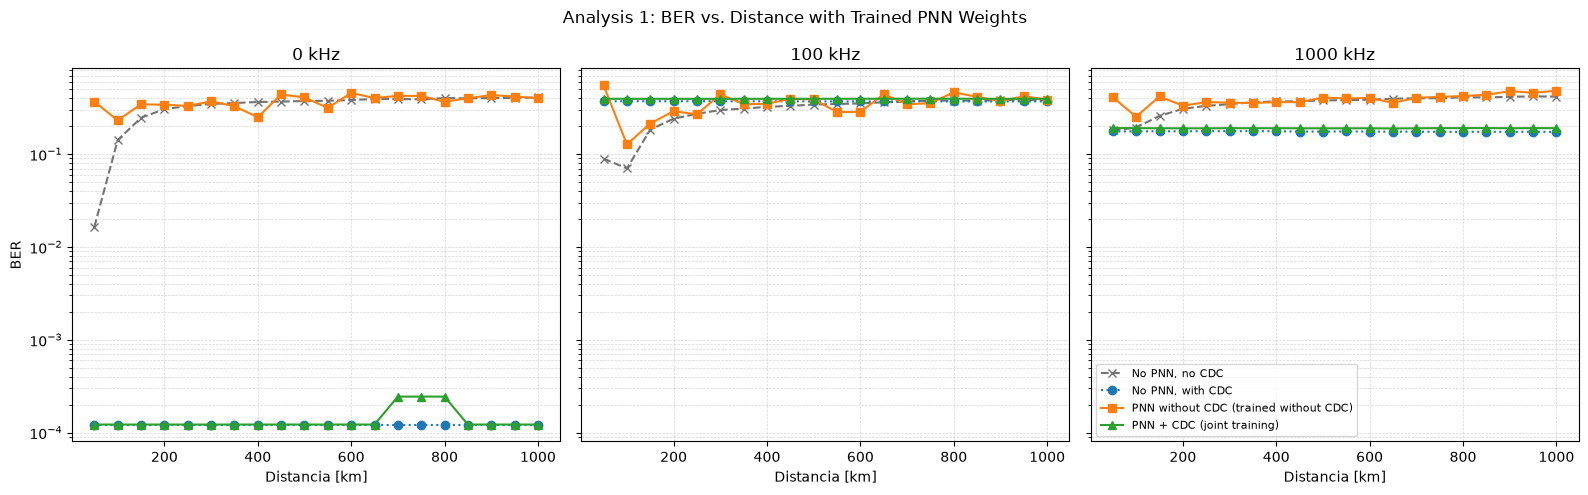

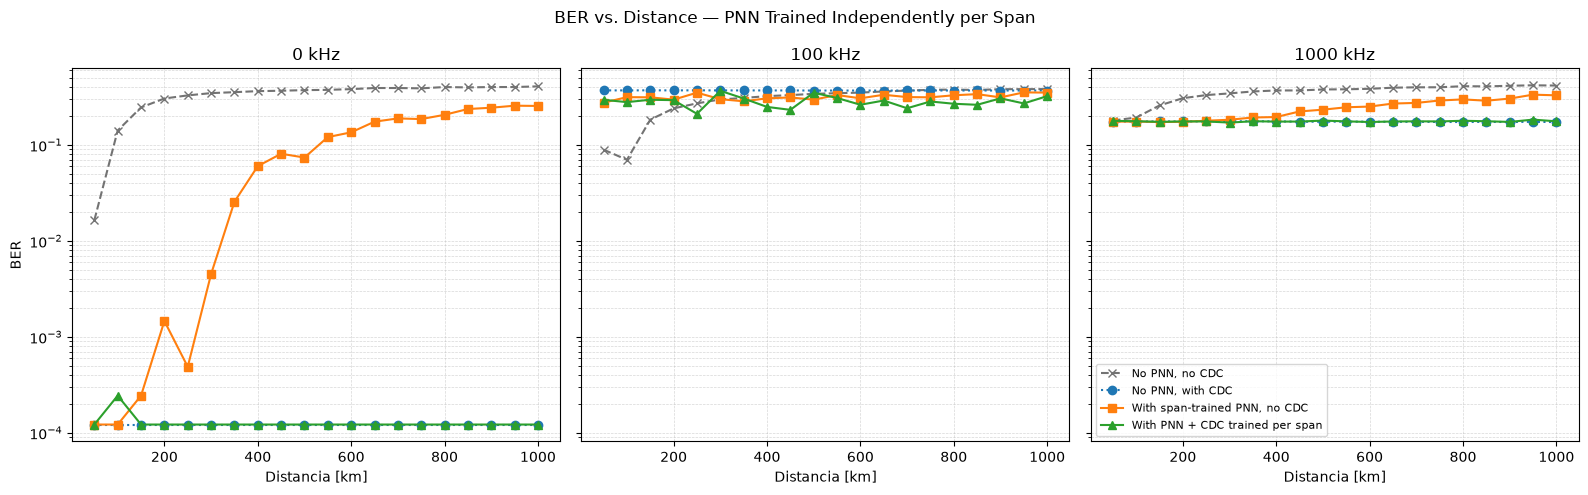

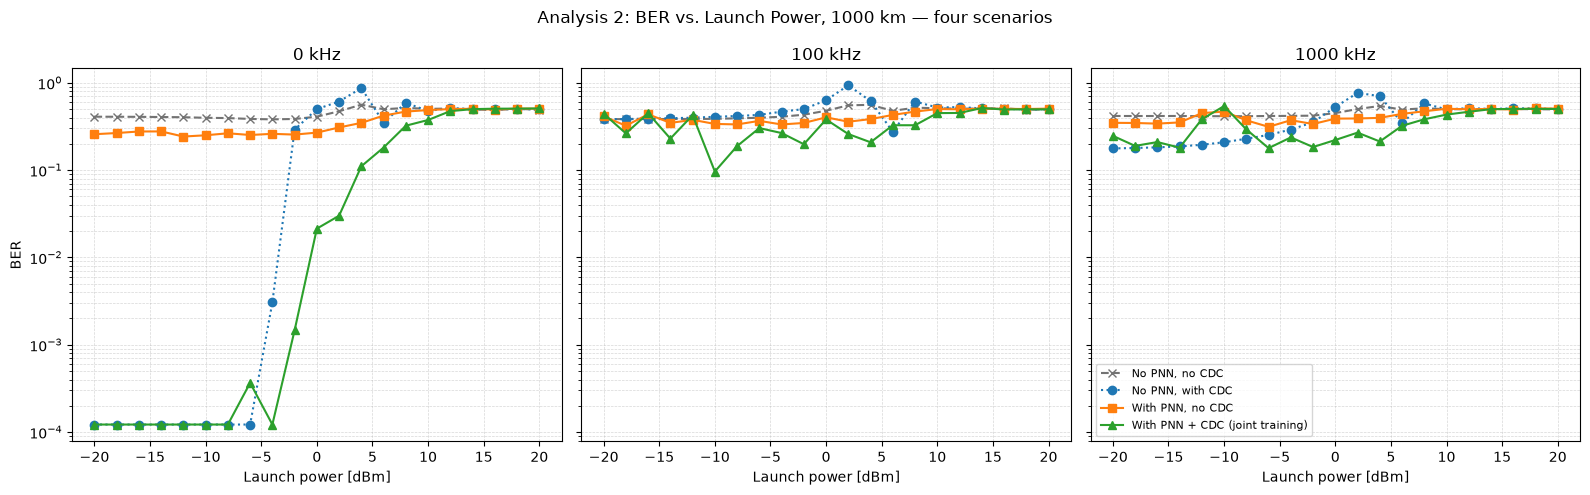

PNN evaluation added to record: D:\gits\PHOTONICS_2026\Codigos\python\pnn_coerente\artifacts\models\pnn_coerente_pso_treinamento.json


In [8]:
# Analysis 1: weights trained at maximum distance and fixed across the curve.
pnn_ber_vs_distance_no_cdc = {float(lw): [] for lw in LINEWIDTHS_HZ}
pnn_ber_vs_distance_with_cdc = {float(lw): [] for lw in LINEWIDTHS_HZ}
pnn_ber_vs_distance_per_span_no_cdc = {float(lw): [] for lw in LINEWIDTHS_HZ}
pnn_ber_vs_distance_per_span_with_cdc = {float(lw): [] for lw in LINEWIDTHS_HZ}
for linewidth_hz in LINEWIDTHS_HZ:
    linewidth_key = float(linewidth_hz)
    phase_tx, phase_lo = phase_noise[linewidth_key]
    trained = pnn_training_results[('dispersion', linewidth_key)]
    pnn_model.set_weights(trained['amplitude_weights'], trained['phase_weights'])
    for distance_km in DISTANCES_KM:
        field_tx = u_tx_0dbm * 10.0 ** (TX_POWER_DISPERSION_DBM / 20.0)
        field_tx = field_tx * np.exp(1j * phase_tx)
        field_link = propagate_spanned_link(
            field_tx, t, distance_km, include_nonlinearity=False
        )
        field_rx, _, _ = receiver_edfa_and_attenuator(field_link)
        _, field_pnn = pnn_model.forward(
            field_rx, dt_s=dt, return_optical_field=True
        )
        r_pnn = coherent_detection(field_pnn, phase_lo=phase_lo)
        rx_pnn_symbols = sample_to_symbols(r_pnn, sps=SPS)
        pnn_ber_vs_distance_no_cdc[linewidth_key].append(
            calculate_ber(bits, demap_qpsk(rx_pnn_symbols))
        )
        joint_trained = pnn_joint_cdc_results[('dispersion', linewidth_key)]
        pnn_model.set_weights(joint_trained['amplitude_weights'], joint_trained['phase_weights'])
        _, joint_field = pnn_model.forward(field_rx, dt_s=dt, return_optical_field=True)
        r_joint_pnn = coherent_detection(joint_field, phase_lo=phase_lo)
        r_joint_pnn_cdc = cd_compensation(r_joint_pnn, dt=dt, length_km=distance_km, dispersion_d=FIBER_PARAMS.d_1550)
        joint_symbols_cdc = sample_to_symbols(r_joint_pnn_cdc, sps=SPS)
        pnn_ber_vs_distance_with_cdc[linewidth_key].append(
            calculate_ber(bits, demap_qpsk(joint_symbols_cdc))
        )

        # Models trained specifically for this sweep span.
        span_models = distance_sweep_training_results[(float(distance_km), linewidth_key)]
        pnn_model.set_weights(
            span_models['pnn_only']['amplitude_weights'],
            span_models['pnn_only']['phase_weights'],
        )
        _, span_field = pnn_model.forward(field_rx, dt_s=dt, return_optical_field=True)
        span_r = coherent_detection(span_field, phase_lo=phase_lo)
        pnn_ber_vs_distance_per_span_no_cdc[linewidth_key].append(
            calculate_ber(bits, demap_qpsk(sample_to_symbols(span_r, sps=SPS)))
        )

        pnn_model.set_weights(
            span_models['pnn_plus_cdc']['amplitude_weights'],
            span_models['pnn_plus_cdc']['phase_weights'],
        )
        _, span_joint_field = pnn_model.forward(field_rx, dt_s=dt, return_optical_field=True)
        span_joint_r = coherent_detection(span_joint_field, phase_lo=phase_lo)
        span_joint_r = cd_compensation(
            span_joint_r, dt=dt, length_km=distance_km,
            dispersion_d=FIBER_PARAMS.d_1550,
        )
        pnn_ber_vs_distance_per_span_with_cdc[linewidth_key].append(
            calculate_ber(bits, demap_qpsk(sample_to_symbols(span_joint_r, sps=SPS)))
        )

fig, axes = plt.subplots(1, len(LINEWIDTHS_HZ), figsize=(16, 5), sharey=True)
for ax, linewidth_hz in zip(axes, LINEWIDTHS_HZ):
    key = float(linewidth_hz)
    ax.semilogy(
        DISTANCES_KM,
        np.maximum(ber_vs_distance_no_cdc[key], BER_PLOT_FLOOR),
        '--x', color='0.45', label='No PNN, no CDC',
    )
    ax.semilogy(
        DISTANCES_KM,
        np.maximum(ber_vs_distance_with_cdc[key], BER_PLOT_FLOOR),
        ':o', color='tab:blue', label='No PNN, with CDC',
    )
    ax.semilogy(
        DISTANCES_KM,
        np.maximum(pnn_ber_vs_distance_no_cdc[key], BER_PLOT_FLOOR),
        '-s', color='tab:orange', label='PNN without CDC (trained without CDC)',
    )
    ax.semilogy(
        DISTANCES_KM,
        np.maximum(pnn_ber_vs_distance_with_cdc[key], BER_PLOT_FLOOR),
        '-^', color='tab:green', label='PNN + CDC (joint training)',
    )
    ax.set_title(f'{linewidth_hz/1e3:g} kHz')
    ax.set_xlabel('Distancia [km]')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
axes[0].set_ylabel('BER')
axes[-1].legend(fontsize=8, loc='best')
fig.suptitle('Analysis 1: BER vs. Distance with Trained PNN Weights')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pnn_analise_1_ber_distancia_com_pnn.png', dpi=250)
plt.show()

# Comparison using PNN weights retrained independently at each distance.
fig, axes = plt.subplots(1, len(LINEWIDTHS_HZ), figsize=(16, 5), sharey=True)
for ax, linewidth_hz in zip(axes, LINEWIDTHS_HZ):
    key = float(linewidth_hz)
    ax.semilogy(DISTANCES_KM, np.maximum(ber_vs_distance_no_cdc[key], BER_PLOT_FLOOR), '--x', color='0.45', label='No PNN, no CDC')
    ax.semilogy(DISTANCES_KM, np.maximum(ber_vs_distance_with_cdc[key], BER_PLOT_FLOOR), ':o', color='tab:blue', label='No PNN, with CDC')
    ax.semilogy(DISTANCES_KM, np.maximum(pnn_ber_vs_distance_per_span_no_cdc[key], BER_PLOT_FLOOR), '-s', color='tab:orange', label='With span-trained PNN, no CDC')
    ax.semilogy(DISTANCES_KM, np.maximum(pnn_ber_vs_distance_per_span_with_cdc[key], BER_PLOT_FLOOR), '-^', color='tab:green', label='With PNN + CDC trained per span')
    ax.set_title(f'{linewidth_hz/1e3:g} kHz')
    ax.set_xlabel('Distancia [km]')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
axes[0].set_ylabel('BER')
axes[-1].legend(fontsize=8, loc='best')
fig.suptitle('BER vs. Distance — PNN Trained Independently per Span')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pnn_analise_1_ber_distancia_treino_por_span.png', dpi=250)
plt.show()

# Analysis 2: both PNN types are specialized for each launch power.
pnn_ber_vs_power_retrained_no_cdc = {float(lw): [] for lw in LINEWIDTHS_HZ}
pnn_ber_vs_power_retrained_with_cdc = {float(lw): [] for lw in LINEWIDTHS_HZ}
for launch_power_dbm in POWER_SWEEP_DBM:
    tx_field = u_tx_0dbm * 10.0 ** (launch_power_dbm / 20.0)
    for linewidth_hz in LINEWIDTHS_HZ:
        linewidth_key = float(linewidth_hz)
        phase_tx, phase_lo = phase_noise[linewidth_key]
        field_tx = tx_field * np.exp(1j * phase_tx)
        field_link = propagate_spanned_link(field_tx, t, DISTANCE_NONLINEAR_KM, include_nonlinearity=True)
        field_rx, _, _ = receiver_edfa_and_attenuator(field_link)

        # PNN trained using BER before CDC.
        pnn_only = pnn_power_training_results[(float(launch_power_dbm), linewidth_key)]
        pnn_model.set_weights(pnn_only['amplitude_weights'], pnn_only['phase_weights'])
        _, field_pnn_only = pnn_model.forward(field_rx, dt_s=dt, return_optical_field=True)
        r_pnn_only = coherent_detection(field_pnn_only, phase_lo=phase_lo)
        pnn_ber_vs_power_retrained_no_cdc[linewidth_key].append(
            calculate_ber(bits, demap_qpsk(sample_to_symbols(r_pnn_only, sps=SPS)))
        )

        # PNN trained with CDC in the objective; CDC is also applied during evaluation.
        pnn_joint = pnn_power_joint_cdc_results[(float(launch_power_dbm), linewidth_key)]
        pnn_model.set_weights(pnn_joint['amplitude_weights'], pnn_joint['phase_weights'])
        _, field_pnn_joint = pnn_model.forward(field_rx, dt_s=dt, return_optical_field=True)
        r_pnn_joint = coherent_detection(field_pnn_joint, phase_lo=phase_lo)
        r_pnn_joint_cdc = cd_compensation(r_pnn_joint, dt=dt, length_km=DISTANCE_NONLINEAR_KM, dispersion_d=FIBER_PARAMS.d_1550)
        pnn_ber_vs_power_retrained_with_cdc[linewidth_key].append(
            calculate_ber(bits, demap_qpsk(sample_to_symbols(r_pnn_joint_cdc, sps=SPS)))
        )

fig, axes = plt.subplots(1, len(LINEWIDTHS_HZ), figsize=(16, 5), sharey=True)
for ax, linewidth_hz in zip(axes, LINEWIDTHS_HZ):
    key = float(linewidth_hz)
    ax.semilogy(POWER_SWEEP_DBM, np.maximum(ber_vs_power_no_cdc[key], BER_PLOT_FLOOR), '--x', color='0.45', label='No PNN, no CDC')
    ax.semilogy(POWER_SWEEP_DBM, np.maximum(ber_vs_power_with_cdc[key], BER_PLOT_FLOOR), ':o', color='tab:blue', label='No PNN, with CDC')
    ax.semilogy(POWER_SWEEP_DBM, np.maximum(pnn_ber_vs_power_retrained_no_cdc[key], BER_PLOT_FLOOR), '-s', color='tab:orange', label='With PNN, no CDC')
    ax.semilogy(POWER_SWEEP_DBM, np.maximum(pnn_ber_vs_power_retrained_with_cdc[key], BER_PLOT_FLOOR), '-^', color='tab:green', label='With PNN + CDC (joint training)')
    ax.set_title(f'{linewidth_hz/1e3:g} kHz')
    ax.set_xlabel('Launch power [dBm]')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
axes[0].set_ylabel('BER')
axes[-1].legend(fontsize=8, loc='best')
fig.suptitle(f'Analysis 2: BER vs. Launch Power, {DISTANCE_NONLINEAR_KM:g} km — four scenarios')
fig.tight_layout()
fig.savefig(FIG_DIR / 'pnn_analise_2_ber_potencia_quatro_cenarios.png', dpi=250)
plt.show()

# Add evaluation BER values to the weights/checkpoint file.
for scenario, curves in [
    ('dispersion', pnn_ber_vs_distance_no_cdc),
    
]:
    for item in pnn_training_record['results']:
        if item['scenario'] != scenario:
            continue
        key = float(item['linewidth_hz'])
        item['evaluation_ber_without_cdc'] = [float(v) for v in curves[key]]
pnn_training_record['distance_sweep_km'] = DISTANCES_KM.tolist()
pnn_training_record['evaluation_ber_distance_per_span_no_cdc'] = {
    str(key): [float(v) for v in values]
    for key, values in pnn_ber_vs_distance_per_span_no_cdc.items()
}
pnn_training_record['evaluation_ber_distance_per_span_with_cdc'] = {
    str(key): [float(v) for v in values]
    for key, values in pnn_ber_vs_distance_per_span_with_cdc.items()
}
pnn_training_record['power_sweep_dbm'] = POWER_SWEEP_DBM.tolist()
pnn_training_record['evaluation_ber_with_cdc_distance'] = {
    str(key): [float(v) for v in values]
    for key, values in pnn_ber_vs_distance_with_cdc.items()
}
pnn_training_record['evaluation_ber_with_cdc_power'] = {
    str(key): [float(v) for v in values]
    for key, values in pnn_ber_vs_power_retrained_with_cdc.items()
}
pnn_training_record['evaluation_ber_power_retrained_without_cdc'] = {
    str(key): [float(v) for v in values]
    for key, values in pnn_ber_vs_power_retrained_no_cdc.items()
}
pnn_training_record['power_curve_semantics'] = {
    'baseline_no_cdc': 'no PNN and no CDC',
    'baseline_with_cdc': 'no PNN and with CDC',
    'pnn_no_cdc': 'PNN trained without CDC at each power',
    'pnn_with_cdc': 'PNN trained with CDC at each power; CDC applied during evaluation',
}
pnn_training_record['evaluation_ber_power_retrained_with_cdc'] = {
    str(key): [float(v) for v in values]
    for key, values in pnn_ber_vs_power_retrained_with_cdc.items()
}
PNN_RESULT_PATH.write_text(json.dumps(pnn_training_record, indent=2), encoding='utf-8')
print(f'PNN evaluation added to record: {PNN_RESULT_PATH}')


## Notes and Next Steps

- Span lengths are uniform. For example, `SPAN_LENGTH_KM = 200` over a 1000 km link produces exactly five 200 km spans.
- A fixed terminal EDFA followed by variable attenuation maintains 0 dBm receiver power. The value is printed after the analyses for verification.
- `EDFAIdeal` in `src/utils/edfa.py` applies fixed field gain without ASE or saturation. The same method is used for inline and terminal amplification. It can be replaced through `EDFA_MODEL`. Adding ASE/noise figure effects is a possible next study.
- Both analyses show BER with and without conventional CDC. CDC is applied digitally after coherent detection and before symbol decisions; in the nonlinear case, it removes second-order dispersion but does not undo Kerr effects.
- Sections 6 and 7 train and evaluate PNNs separately by scenario and linewidth. The power sweep includes both a fixed PNN trained at 0 dBm and specialized PNNs trained at each sweep point.
- The distance analysis also trains independent models at each span distance, in addition to evaluating models trained only at the maximum distance.